# Logistic Regression və Regularization — praktiki notebook

**Məqsəd:** Nəzəri konspektdəki anlayışları özün icra edib qrafiklər və metrikalar üzərində görmək. Nümunələr sintetik və sklearn-in daxili dataset-lərindən istifadə edir; internet tələb etmir.

**Vacib:** Kodlar hazır cavabı əzbərləmək üçün deyil. Hər blokdan sonra `Niyə?` sualına cavab verməyə çalış.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, mean_squared_error, r2_score)
print("Kitabxanalar yükləndi")

Kitabxanalar yükləndi


## 1. Sigmoid funksiyası

`z` bütün real ədədlər ola bilər, lakin sigmoid onu `(0,1)` aralığına keçirir. `z=0` üçün ehtimal `0.5`-dir.

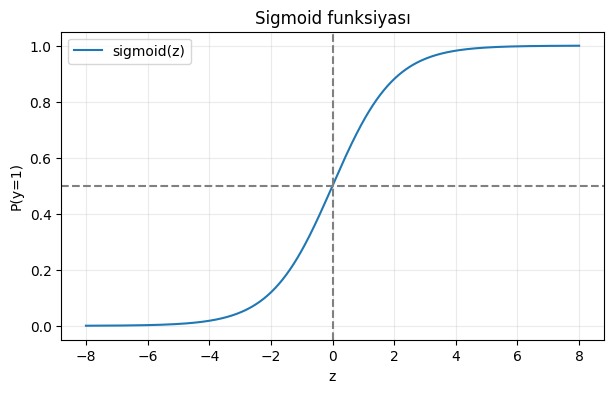

sigmoid(0) = 0.5


In [2]:
z = np.linspace(-8, 8, 400)
p = 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z, p, label="sigmoid(z)")
ax.axhline(0.5, linestyle="--", color="gray")
ax.axvline(0, linestyle="--", color="gray")
ax.set(xlabel="z", ylabel="P(y=1)", title="Sigmoid funksiyası")
ax.legend(); ax.grid(alpha=0.25); plt.show()
print("sigmoid(0) =", 1 / (1 + np.exp(0)))

## 2. Klassifikasiya: düzgün train/test + Pipeline

**Niyə `stratify=y`?** Sinif paylarını bölünmələrdə yaxın saxlamaq üçün. **Niyə Pipeline?** Testin statistikasının scaler-ə sızmasını önləmək üçün.

In [3]:
X, y = make_classification(n_samples=700, n_features=8, n_informative=4,
                           n_redundant=2, weights=[0.75, 0.25], flip_y=0.03, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
classifier = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
classifier.fit(X_train, y_train)
probabilities = classifier.predict_proba(X_test)[:, 1]
print("Train ölçüsü:", X_train.shape, "Test ölçüsü:", X_test.shape)
print("İlk 5 ehtimal:", np.round(probabilities[:5], 3))

Train ölçüsü: (525, 8) Test ölçüsü: (175, 8)
İlk 5 ehtimal: [0.887 0.72  0.733 0.328 0.309]


## 3. Threshold, Confusion Matrix və metrikalar

`confusion_matrix` sklearn-də `[0,1]` sırası ilə `[[TN, FP],[FN, TP]]` qaytarır. Həddin dəyişməsinin **Recall və Precision** üzərindəki təsirinə bax.

In [4]:
results = []
for threshold in [0.3, 0.5, 0.7]:
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    results.append({"threshold": threshold, "TP": tp, "TN": tn, "FP": fp, "FN": fn,
                    "accuracy": accuracy_score(y_test, y_pred),
                    "precision": precision_score(y_test, y_pred, zero_division=0),
                    "recall": recall_score(y_test, y_pred, zero_division=0),
                    "f1": f1_score(y_test, y_pred, zero_division=0)})
print(pd.DataFrame(results).round(3).to_string(index=False))

 threshold  TP  TN  FP  FN  accuracy  precision  recall    f1
       0.3  34  97  32  12     0.749      0.515   0.739 0.607
       0.5  13 120   9  33     0.760      0.591   0.283 0.382
       0.7   9 126   3  37     0.771      0.750   0.196 0.310


## 4. Logistic Regression: `C` nə edir?

**Kiçik `C` → daha güclü regularization.** Əmsalların L2 normasına bax; bu nümunədə dəqiq hansı modelin testdə yaxşı olması dataset-dən asılıdır.

In [5]:
for C in [0.05, 1, 100]:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    pipe.fit(X_train, y_train)
    coef_norm = np.linalg.norm(pipe.named_steps["logisticregression"].coef_)
    f1 = f1_score(y_test, pipe.predict(X_test))
    print(f"C={C:6} | ||w||={coef_norm:.3f} | Test F1={f1:.3f}")

C=  0.05 | ||w||=1.110 | Test F1=0.355


C=     1 | ||w||=1.859 | Test F1=0.382
C=   100 | ||w||=1.944 | Test F1=0.400


## 5. Ridge, Lasso və ElasticNet — reqressiya

Bu blokda **fərqli bir reqressiya datası** istifadə olunur. Klassifikasiya qiymətləndirməsi ilə qarışdırma. `StandardScaler` yalnız train-ə fit edilir.

In [6]:
Xr, yr = make_regression(n_samples=400, n_features=12, n_informative=4,
                         noise=22, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.25, random_state=42)
models = {
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=10.0, max_iter=30000),
    "ElasticNet": ElasticNet(alpha=10.0, l1_ratio=0.5, max_iter=30000),
}
rows = []
for name, estimator in models.items():
    model = make_pipeline(StandardScaler(), estimator)
    model.fit(Xr_train, yr_train)
    yp = model.predict(Xr_test)
    w = model.steps[-1][1].coef_
    rows.append({"model": name, "RMSE": np.sqrt(mean_squared_error(yr_test, yp)),
                 "R2": r2_score(yr_test, yp), "sıfır əmsal sayı": int(np.sum(np.isclose(w, 0, atol=1e-6)))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

     model   RMSE    R2  sıfır əmsal sayı
     Ridge 21.489 0.963                 0
     Lasso 29.577 0.931                 8
ElasticNet 96.375 0.265                 5


## 6. Regularization gücünün təsiri

`alpha` artdıqca Ridge-də əmsallar adətən kiçilir. Bunun test xətasına təsiri həmişə monoton yaxşılaşmır.

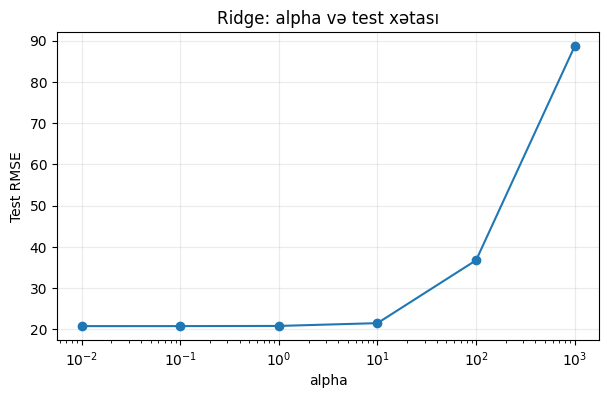

  alpha   RMSE   ||w||
   0.01 20.766 116.198
   0.10 20.770 116.162
   1.00 20.811 115.802
  10.00 21.489 112.325
 100.00 36.745  86.513
1000.00 88.674  26.475


In [7]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]
rmse_values, norm_values = [], []
for alpha in alphas:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(Xr_train, yr_train)
    yp = model.predict(Xr_test)
    rmse_values.append(np.sqrt(mean_squared_error(yr_test, yp)))
    norm_values.append(np.linalg.norm(model.named_steps["ridge"].coef_))
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(alphas, rmse_values, marker="o")
ax.set(xlabel="alpha", ylabel="Test RMSE", title="Ridge: alpha və test xətası")
ax.grid(alpha=0.25); plt.show()
print(pd.DataFrame({"alpha": alphas, "RMSE": rmse_values, "||w||": norm_values}).round(3).to_string(index=False))

## 7. PolynomialFeatures və Pipeline

Çevik model qurmaq bəzən faydalıdır, bəzən də overfitting verir. `PolynomialFeatures` dərəcəsini şişirtmə; seçim üçün validation/cross-validation istifadə et. Buradakı test müqayisəsi **tədris məqsədlidir**; onun əsasında hiperparametr seçməməlisən.

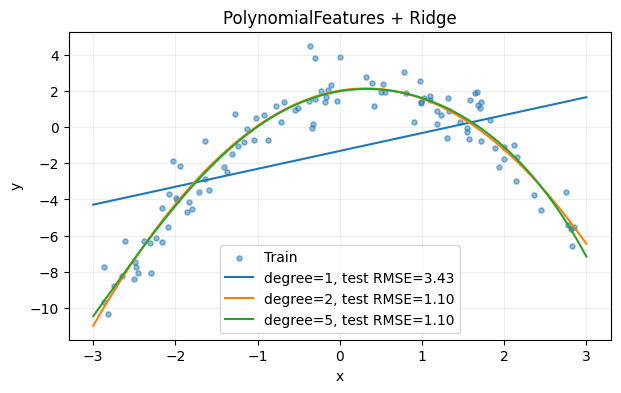

In [8]:
rng = np.random.default_rng(42)
x = rng.uniform(-3, 3, size=140).reshape(-1, 1)
y_curve = 2 + 0.7*x[:, 0] - 1.2*x[:, 0]**2 + rng.normal(0, 1, size=140)
xc_train, xc_test, yc_train, yc_test = train_test_split(
    x, y_curve, test_size=0.25, random_state=42)
xx = np.linspace(-3, 3, 200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xc_train[:, 0], yc_train, s=14, alpha=0.5, label="Train")
for degree in [1, 2, 5]:
    pipe = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                         StandardScaler(), Ridge(alpha=1.0))
    pipe.fit(xc_train, yc_train)
    yp = pipe.predict(xc_test)
    ax.plot(xx[:, 0], pipe.predict(xx), label=f"degree={degree}, test RMSE={np.sqrt(mean_squared_error(yc_test, yp)):.2f}")
ax.set(xlabel="x", ylabel="y", title="PolynomialFeatures + Ridge")
ax.legend(); ax.grid(alpha=0.2); plt.show()

## 8. Özün cavablandır

1. `threshold=0.3` olduqda nə üçün FN sayı azala bilər?
2. `C=0.05` və `C=100` əmsal norması arasında nə fərq var və niyə?
3. Lasso-nun hansı `alpha` dəyərində əmsalları daha çox sıfırlanır? Kodla yoxla.
4. `degree=2` və `degree=5` nəticələrini müqayisə edəndə testə baxaraq seçim etmək niyə risklidir?
5. Niyə `R²` Logistic Regression üçün standart qiymətləndirmə göstəricisi deyil?

**Qeyd:** Real iş axınında hiperparametr seçimini yalnız train daxilində cross-validation ilə et, testə yekun qiymətləndirmə üçün bir dəfə bax.

**Mənbə:** `AI_LogisticRegression_Regularization_Nezeri_Tapsiriq.pdf` (s. 1–2); sklearn-in rəsmi sənədləri, linklər Markdown konspektindədir.